# Cylinders modeled as multi-domain assemblies

This example computes the linear buckling load of a laminated cylinder under axial compression, modeled with five domains around the circumference, and compares it with the literature. It then adds blade stiffeners to a cylinder. Both methods that connect the domains are used.

A `MultiDomain` assembly connects `Shell` domains, each with its own Ritz series, see `panels.multidomain.connections` and Castro and Donadon (2017). The function `create_cylinder` creates a cylinder with panels along its circumference, all in the group `'skin'`, and connects the last panel to the first one to close it. The connections impose the continuity of the displacements and rotations along the shared edges. With `conn_method='null-space'` they are imposed exactly, as linear constraints whose null space gives the independent unknowns, see [Exact connections with the null-space method](../multidomain_null_space.rst). With `conn_method='penalty'`, penalty stiffnesses approximate them, with the default constants of `calc_kt_kr`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import lb
from panels.multidomain.cylinder import create_cylinder
from panels.multidomain import (cylinder_compression_lb_Nxx_from_static,
        cylinder_blade_stiffened_compression_lb_Nxx_from_static)


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_group(md, c, group, ax, field='w', title=''):
    """Contour of ``field`` on the domains of ``group``, unrolled, with the
    circumferential coordinate along the horizontal axis"""
    panels = [p for p in md.panels if p.group == group]
    res = md.uvw(c, group, gridx=30, gridy=30)
    vmax = max(np.abs(f).max() for f in res[field])
    levels = np.linspace(-vmax, vmax, 31)
    for p, x, y, f in zip(panels, res['x'], res['y'], res[field]):
        cf = ax.contourf(y + p.y0, x + p.x0, f, levels=levels, cmap='coolwarm')
        ax.plot([p.y0, p.y0], [p.x0, p.x0 + p.a], 'k-', lw=0.5)
    ax.set_xlabel('circumferential coordinate $y$ (m)')
    ax.set_ylabel('axial coordinate $x$ (m)')
    ax.set_title(title)
    ax.set_aspect('equal')
    return cf

## Cylinder Z11 under a constant pre-buckling stress

The cylinder is Z11 of Geier et al., as given by Castro et al. (2014), Tables 3 and 4: radius $R = 250$ mm, length $H = 510$ mm, ten plies of 0.125 mm, $[\pm 60/0_2/\pm 68/\pm 52/\pm 37]$ from the inner to the outer surface, of a carbon/epoxy with $(E_{11}, E_{22}, \nu_{12}, G_{12}, G_{13}, G_{23}) = (123.55, 8.708, 0.319, 5.695, 5.695, 3.400)$ GPa/-. Castro et al. (2014), Table 6, give the critical axial force of Z11 with the classical laminated plate theory (CLPT) and the simply supported edges SS2 ($v = w = 0$, $u$ free) at both ends: 288.74 kN from Geier et al. and 288.73 kN from their own model. These values assume an orthotropic laminate: the terms $A_{16}, A_{26}, B_{16}, B_{26}, D_{16}, D_{26}$ of the constitutive matrix are set to zero. In panels this is `force_orthotropic_laminate = True`.

Each of the five domains has a constant axial stress resultant `Nxx` = -1 N/m, and the linear buckling problem $(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0}$ is solved, as in `cylinder_compression_lb_Nxx_cte`, whose code the function below repeats to set the orthotropic flag. The critical axial force is $P_{cr} = -\lambda N_{xx} 2 \pi R$. `create_cylinder` gives the edge SS1 ($u = v = w = 0$) at $x = 0$, and `x2u = 1` makes the edge $x = H$ SS2; the axial displacement $u$ must be restrained somewhere to remove the rigid-body translation. Castro et al. (2014), Fig. 5, show that this condition changes little: 288.99 kN with SS1 at one end and CC1 at the other. The kinematics are Sanders', the default for cylinders, where Castro et al. (2014) use Donnell's.

In [2]:
R = 0.25
Z11 = dict(height=0.51, r=R, plyt=0.125e-3,
           stack=[60, -60, 0, 0, 68, -68, 52, -52, 37, -37],
           laminaprop=(123.55e9, 8.708e9, 0.319, 5.695e9, 5.695e9, 3.400e9),
           npanels=5)


def z11_lb(conn_method, orthotropic, m, n, Nxx=-1.):
    """Critical axial force (N) and first mode for a constant Nxx"""
    md, conns = create_cylinder(m=m, n=n, conn_method=conn_method, **Z11)
    for p in md.panels:
        p.Nxx = Nxx
        p.x2u = 1  # SS2 at x = H
        p.force_orthotropic_laminate = orthotropic
    k0 = md.reduce(md.calc_kC(conns, silent=True))
    kG = md.reduce(md.calc_kG(silent=True))
    eigvals, eigvecs = lb(k0, kG, tol=0, sparse_solver=True, silent=True,
                          num_eigvalues=5)
    return md, -Nxx*eigvals[0]*2*np.pi*R, md.expand(eigvecs)[:, 0]


results = {}
modes = {}
for method, m in (('null-space', 12), ('null-space', 16), ('null-space', 20),
                  ('penalty', 16)):
    md, Pcr, mode = z11_lb(method, True, m, m)
    results[('orthotropic', method, m)] = Pcr
    modes[('orthotropic', method, m)] = (md, mode)
    print('%-10s, %2d x %2d terms, %5d Ritz constants: P_cr = %.2f kN'
          % (method, m, m, md.get_size(), Pcr/1e3))

null-space, 12 x 12 terms,  2160 Ritz constants: P_cr = 288.99 kN


null-space, 16 x 16 terms,  3840 Ritz constants: P_cr = 288.43 kN


null-space, 20 x 20 terms,  6000 Ritz constants: P_cr = 288.32 kN


penalty   , 16 x 16 terms,  3840 Ritz constants: P_cr = 287.86 kN


## Full constitutive matrix

Without the orthotropic assumption the coupling terms $B_{16}, B_{26}, D_{16}, D_{26}$ of the laminate are kept. Castro et al. (2014), Fig. 4, show that the critical force of Z11 drops by 3%, to 280.08 kN, and that the mode changes from a pattern of rectangular cells to a helical pattern.

In [3]:
for method in ('null-space', 'penalty'):
    md, Pcr, mode = z11_lb(method, False, 16, 16)
    results[('full matrix', method, 16)] = Pcr
    modes[('full matrix', method, 16)] = (md, mode)
    print('%-10s, 16 x 16 terms: P_cr = %.2f kN' % (method, Pcr/1e3))

null-space, 16 x 16 terms: P_cr = 279.14 kN


penalty   , 16 x 16 terms: P_cr = 278.69 kN


## Pre-buckling stress from a static analysis

`cylinder_compression_lb_Nxx_from_static` applies the compression as a load distributed at the end $x = H$ of each panel. It solves the linear static problem and computes $\boldsymbol{K}_G$ from the Ritz constants of that solution. The stress field then follows the boundary conditions at the ends, where the restrained radial displacement bends the wall, a state that the constant `Nxx` above and the reference values neglect. The full constitutive matrix is used.

In [4]:
md, c, eigvals, eigvecs = cylinder_compression_lb_Nxx_from_static(
    Nxxs=[-1.]*5, m=16, n=16, num_eigvalues=5, conn_method='null-space',
    **Z11)
results[('Nxx from static', 'null-space', 16)] = eigvals[0]*2*np.pi*R
modes[('Nxx from static', 'null-space', 16)] = (md, eigvecs[:, 0])
print('P_cr = %.2f kN' % (eigvals[0]*2*np.pi*R/1e3))

		Calculating kG for assembly...
		Calculating kG... 


		finished!
		Calculating kG... 


		finished!
		Calculating kG... 


		finished!
		Calculating kG... 


		finished!
		Calculating kG... 


		finished!
		finished!


P_cr = 279.32 kN


## Blade-stiffened cylinder

Blade stiffeners, one per panel, are added along the length of a cylinder as further domains connected to the skin, see `create_cylinder_blade_stiffened`. This cylinder has $r = 0.25$ m, length 0.5 m and the skin $[0/45/-45/90/-45/45]$ of plies of 0.125 mm, $(E_{11}, E_{22}, \nu_{12}, G_{12}, G_{13}, G_{23}) = (142.5, 8.7, 0.28, 5.1, 5.1, 5.1)$ GPa/-, with five domains of $8 \times 12$ terms. The blade domains are 20 mm wide, `width_blades`, with the laminate $[0/90/0]_4$. They carry the same axial compression as the skin, `Nxx` = -100 N/m, and the pre-buckling state comes from a static analysis.

In [5]:
geometry_blade = dict(height=0.5, r=0.25, plyt=0.125e-3,
                      stack=[0, 45, -45, 90, -45, 45],
                      laminaprop=(142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9),
                      npanels=5, m=8, n=12, num_eigvalues=10)
Nxxs = [-100.]*5
for method in ('penalty', 'null-space'):
    md, c, eigvals, eigvecs = \
        cylinder_blade_stiffened_compression_lb_Nxx_from_static(
            stack_blades=[[0, 90, 0]*4]*5, width_blades=[0.02]*5,
            Nxxs_skin=Nxxs, Nxxs_blade=Nxxs, conn_method=method,
            **geometry_blade)
    results[('blade-stiffened', method)] = Nxxs[0]*eigvals[0]
    modes[('blade-stiffened', method)] = (md, eigvecs[:, 0])
    print('%-10s: critical Nxx = %.3f N/m' % (method, Nxxs[0]*eigvals[0]))

penalty   : critical Nxx = -39993.838 N/m


null-space: critical Nxx = -41696.682 N/m


## Buckling modes

The first buckling modes of the skin, unrolled, with the domain boundaries as vertical lines. The modes of Z11 can be compared with Castro et al. (2014), Fig. 4: rectangular cells with the orthotropic laminate, a helical pattern with the full constitutive matrix.

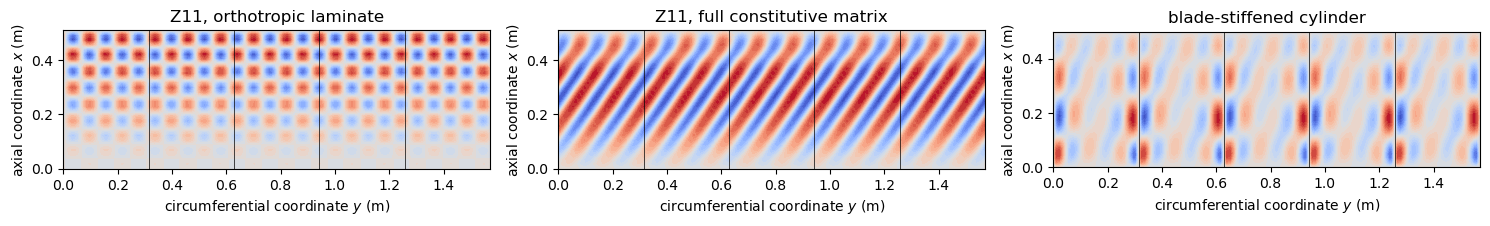

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key, title in zip(axes,
        [('orthotropic', 'null-space', 20), ('full matrix', 'null-space', 16),
         ('blade-stiffened', 'null-space')],
        ['Z11, orthotropic laminate', 'Z11, full constitutive matrix',
         'blade-stiffened cylinder']):
    md, mode = modes[key]
    cf = plot_group(md, mode, 'skin', ax, title=title)
fig.tight_layout()
plt.show()

## Results

The critical forces of Z11 are compared with Castro et al. (2014): Table 6 for the orthotropic laminate (column "Ref. [16] CLPT SS2", the value of Geier et al.) and Fig. 4(b) for the full constitutive matrix (their model CLPT-BC2, SS2). With the null-space method the orthotropic case converges to within 0.2% of the reference, and the full-matrix case lies within 0.4%. The remaining differences come from the kinematics (Sanders' here, Donnell's in the reference), from the edge $x = 0$, where $u = 0$ here, and from the number of terms (Castro et al. use $m = n = 50$ terms in a single domain, Table 6). With the default penalty constants, the connections leave some relative motion at the joints, which lowers the critical force slightly. The static pre-buckling state gives almost the same critical force as the constant one for this cylinder.

No published value is available for the blade-stiffened cylinder. Its two rows compare the two connection methods with the regression values of the panels unit tests `tests/multidomain/test_cylinder_blade_stiffened.py` (penalty, checked there within 0.1%) and `test_null_space.py` (null-space, $10^{-5}$), an internal comparison only. For this cylinder the default penalty constants give a critical load 4% lower than the null-space method, which imposes the connections exactly.

In [7]:
ORTHO = (288.74e3, 'Castro et al. (2014), Table 6, Geier et al., CLPT SS2')
FULL = (280.08e3, 'Castro et al. (2014), Fig. 4(b), CLPT-BC2 SS2')
rows = []
for key, (ref, source) in [(('orthotropic', 'null-space', 20), ORTHO),
                           (('orthotropic', 'penalty', 16), ORTHO),
                           (('full matrix', 'null-space', 16), FULL),
                           (('full matrix', 'penalty', 16), FULL),
                           (('Nxx from static', 'null-space', 16), FULL)]:
    rows.append(('Z11, %s, %s, %d x %d terms, $P_{cr}$ (kN)'
                 % (key[0], key[1], key[2], key[2]),
                 results[key]/1e3, ref/1e3, source))
rows.append(('blade-stiffened, penalty, critical $N_{xx}$ (N/m)',
             results[('blade-stiffened', 'penalty')], -39993.838,
             'regression value, `test_cylinder_blade_stiffened.py`'))
rows.append(('blade-stiffened, null-space, critical $N_{xx}$ (N/m)',
             results[('blade-stiffened', 'null-space')], -41696.682,
             'regression value, `test_null_space.py`'))
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| Z11, orthotropic, null-space, 20 x 20 terms, $P_{cr}$ (kN) | 288.324 | 288.74 | -1.44e-03 | Castro et al. (2014), Table 6, Geier et al., CLPT SS2 |
| Z11, orthotropic, penalty, 16 x 16 terms, $P_{cr}$ (kN) | 287.864 | 288.74 | -3.03e-03 | Castro et al. (2014), Table 6, Geier et al., CLPT SS2 |
| Z11, full matrix, null-space, 16 x 16 terms, $P_{cr}$ (kN) | 279.138 | 280.08 | -3.36e-03 | Castro et al. (2014), Fig. 4(b), CLPT-BC2 SS2 |
| Z11, full matrix, penalty, 16 x 16 terms, $P_{cr}$ (kN) | 278.689 | 280.08 | -4.97e-03 | Castro et al. (2014), Fig. 4(b), CLPT-BC2 SS2 |
| Z11, Nxx from static, null-space, 16 x 16 terms, $P_{cr}$ (kN) | 279.319 | 280.08 | -2.72e-03 | Castro et al. (2014), Fig. 4(b), CLPT-BC2 SS2 |
| blade-stiffened, penalty, critical $N_{xx}$ (N/m) | -39993.8 | -39993.8 | -4.15e-09 | regression value, `test_cylinder_blade_stiffened.py` |
| blade-stiffened, null-space, critical $N_{xx}$ (N/m) | -41696.7 | -41696.7 | +7.12e-09 | regression value, `test_null_space.py` |

## References

1. S. G. P. Castro, C. Mittelstedt, F. A. C. Monteiro, M. A. Arbelo, G. Ziegmann and R. Degenhardt, "Linear buckling predictions of unstiffened laminated composite cylinders and cones under various loading and boundary conditions using semi-analytical models". Composite Structures, 118:303-315, 2014. https://doi.org/10.1016/j.compstruct.2014.07.037.
2. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.